# Analysis of Road Traffic Accidents

## Exploratory Data Analysis (EDA)



### Introduction

Road traffic accidents are an important public-safety problem because they can result in injuries, fatalities, vehicle damage and disruption to road users. Accident patterns can be influenced by factors such as weather, lighting, road conditions, traffic control devices, type of collision, time of day and driver-related causes.

In this analysis, the traffic accident dataset is explored to understand **when and under what conditions crashes occur, which crash types are most common, what factors are associated with injuries, and which contributory causes appear most frequently**. The analysis uses descriptive statistics, data cleaning, univariate analysis, bivariate analysis, correlation analysis and visualizations to identify useful patterns.

# Importing Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('traffic_accidents.csv')
df

,crash_date,traffic_control_device,weather_condition,lighting_condition,first_crash_type,trafficway_type,alignment,roadway_surface_cond,road_defect,crash_type,...,most_severe_injury,injuries_total,injuries_fatal,injuries_incapacitating,injuries_non_incapacitating,injuries_reported_not_evident,injuries_no_indication,crash_hour,crash_day_of_week,crash_month
0,07/29/2023 01:00:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,TURNING,NOT DIVIDED,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,13,7,7
1,08/13/2023 12:11:00 AM,TRAFFIC SIGNAL,CLEAR,"DARKNESS, LIGHTED ROAD",TURNING,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,0,1,8
2,12/09/2021 10:30:00 AM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,10,5,12
3,08/09/2023 07:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,ANGLE,FOUR WAY,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,...,NONINCAPACITATING INJURY,5.0,0.0,0.0,5.0,0.0,0.0,19,4,8
4,08/19/2023 02:55:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,REAR END,T-INTERSECTION,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,3.0,14,7,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209301,09/13/2023 01:08:00 PM,UNKNOWN,UNKNOWN,UNKNOWN,TURNING,FOUR WAY,STRAIGHT AND LEVEL,UNKNOWN,UNKNOWN,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,13,4,9
209302,07/18/2023 02:10:00 PM,UNKNOWN,CLEAR,DAYLIGHT,SIDESWIPE SAME DIRECTION,NOT DIVIDED,STRAIGHT AND LEVEL,DRY,NO DEFECTS,NO INJURY / DRIVE AWAY,...,NO INDICATION OF INJURY,0.0,0.0,0.0,0.0,0.0,2.0,14,3,7
209303,10/23/2019 01:32:00 PM,TRAFFIC SIGNAL,CLEAR,DAYLIGHT,PEDESTRIAN,DIVIDED - W/MEDIAN (NOT RAISED),STRAIGHT ON GRADE,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,...,INCAPACITATING INJURY,2.0,0.0,2.0,0.0,0.0,0.0,13,4,10
209304,06/01/2020 03:23:00 PM,NO CONTROLS,CLEAR,DAYLIGHT,PEDESTRIAN,T-INTERSECTION,STRAIGHT AND LEVEL,DRY,NO DEFECTS,INJURY AND / OR TOW DUE TO CRASH,...,NONINCAPACITATING INJURY,1.0,0.0,0.0,1.0,0.0,1.0,15,2,6


## Dataset Overview

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Rows and columns: (209306, 24)

Column names:
['crash_date', 'traffic_control_device', 'weather_condition', 'lighting_condition', 'first_crash_type', 'trafficway_type', 'alignment', 'roadway_surface_cond', 'road_defect', 'crash_type', 'intersection_related_i', 'damage', 'prim_contributory_cause', 'num_units', 'most_severe_injury', 'injuries_total', 'injuries_fatal', 'injuries_incapacitating', 'injuries_non_incapacitating', 'injuries_reported_not_evident', 'injuries_no_indication', 'crash_hour', 'crash_day_of_week', 'crash_month']

Data types:
crash_date                        object
traffic_control_device            object
weather_condition                 object
lighting_condition                object
first_crash_type                  object
trafficway_type                   object
alignment                         object
roadway_surface_cond              object
road_defect                       object
crash_type                        object
intersection_related_i            object


# Data Cleaning and Preprocessing

In [6]:
# Making a  copy
data = df.copy()

# Convert crash date to datetime
data['crash_date'] = pd.to_datetime(
    data['crash_date'],
    format='%m/%d/%Y %I:%M:%S %p',
    errors='coerce'
)

# Check missing values
print("number of missing values\n",data.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", data.duplicated().sum())

# Remove exact duplicate rows
data = data.drop_duplicates().copy()

# Create useful date-based variables
data['year'] = data['crash_date'].dt.year
data['day_name'] = data['crash_date'].dt.day_name()
data['month_name'] = data['crash_date'].dt.month_name()

# Create injury indicators
data['injury_crash'] = (data['injuries_total'] > 0).astype(int)
data['fatal_crash'] = (data['injuries_fatal'] > 0).astype(int)

print("Shape after duplicate removal:", data.shape)
print("Missing values after cleaning:", data.isnull().sum().sum())
print("Date range:", data['crash_date'].min(), "to", data['crash_date'].max())

number of missing values
 crash_date                       0
traffic_control_device           0
weather_condition                0
lighting_condition               0
first_crash_type                 0
trafficway_type                  0
alignment                        0
roadway_surface_cond             0
road_defect                      0
crash_type                       0
intersection_related_i           0
damage                           0
prim_contributory_cause          0
num_units                        0
most_severe_injury               0
injuries_total                   0
injuries_fatal                   0
injuries_incapacitating          0
injuries_non_incapacitating      0
injuries_reported_not_evident    0
injuries_no_indication           0
crash_hour                       0
crash_day_of_week                0
crash_month                      0
dtype: int64
Duplicate rows: 31
Shape after duplicate removal: (209275, 29)
Missing values after cleaning: 0
Date range: 2013-03-03 16

# Q1. What are the most common crash types?

crash_type
NO INJURY / DRIVE AWAY              117356
INJURY AND / OR TOW DUE TO CRASH     91919
Name: count, dtype: int64

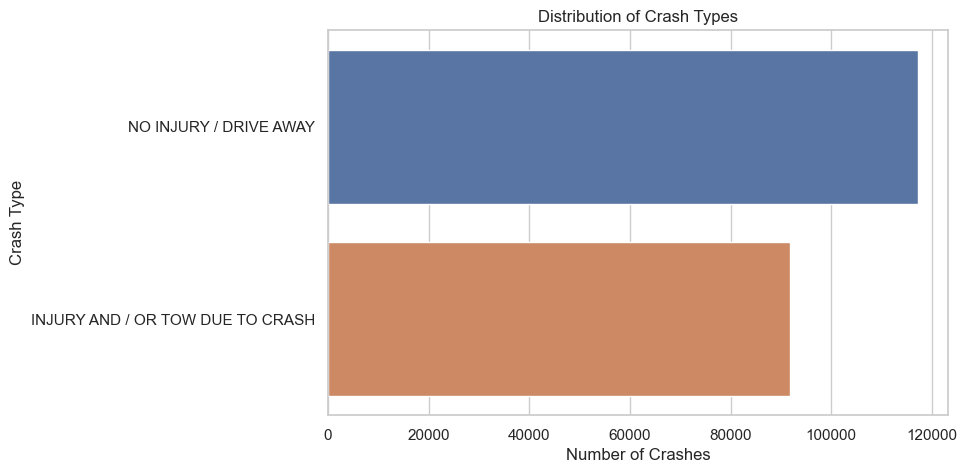

In [4]:
crash_type_counts = data['crash_type'].value_counts()
display(crash_type_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=crash_type_counts.values, y=crash_type_counts.index)
plt.title('Distribution of Crash Types')
plt.xlabel('Number of Crashes')
plt.ylabel('Crash Type')
plt.show()

**Analysis:** The dataset contains more **NO INJURY / DRIVE AWAY** crashes than **INJURY AND / OR TOW DUE TO CRASH** crashes. In the cleaned data, approximately **56.1%** are no-injury/drive-away crashes and **43.9%** are injury/tow-related crashes.

# Q2. Which first-crash types occur most frequently?

first_crash_type
TURNING                         64150
ANGLE                           52243
REAR END                        42007
SIDESWIPE SAME DIRECTION        20114
PEDESTRIAN                       8995
PEDALCYCLIST                     5335
PARKED MOTOR VEHICLE             4892
FIXED OBJECT                     4742
SIDESWIPE OPPOSITE DIRECTION     1839
HEAD ON                          1790
Name: count, dtype: int64

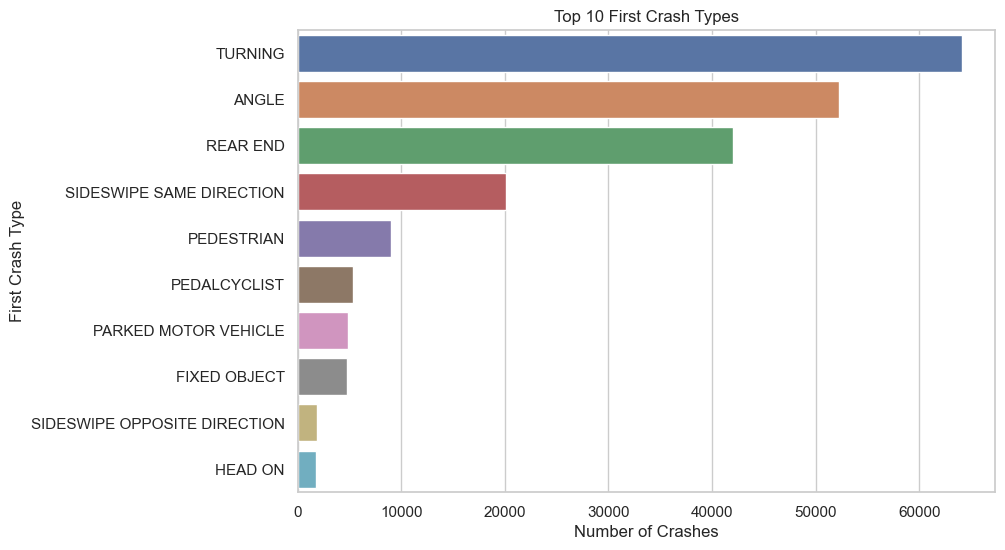

In [5]:
first_type = data['first_crash_type'].value_counts().head(10)
display(first_type)

plt.figure(figsize=(9,6))
sns.barplot(x=first_type.values, y=first_type.index)
plt.title('Top 10 First Crash Types')
plt.xlabel('Number of Crashes')
plt.ylabel('First Crash Type')
plt.show()

**Analysis:** **TURNING, ANGLE and REAR END** are the three most frequent first-crash types. Turning crashes are the largest group, followed by angle and rear-end crashes.

# Q3. Which weather conditions have the most crashes?

weather_condition
CLEAR                       164673
RAIN                         21702
CLOUDY/OVERCAST               7532
SNOW                          6869
UNKNOWN                       6534
OTHER                          627
FREEZING RAIN/DRIZZLE          510
FOG/SMOKE/HAZE                 360
SLEET/HAIL                     308
BLOWING SNOW                   127
SEVERE CROSS WIND GATE          32
BLOWING SAND, SOIL, DIRT         1
Name: count, dtype: int64

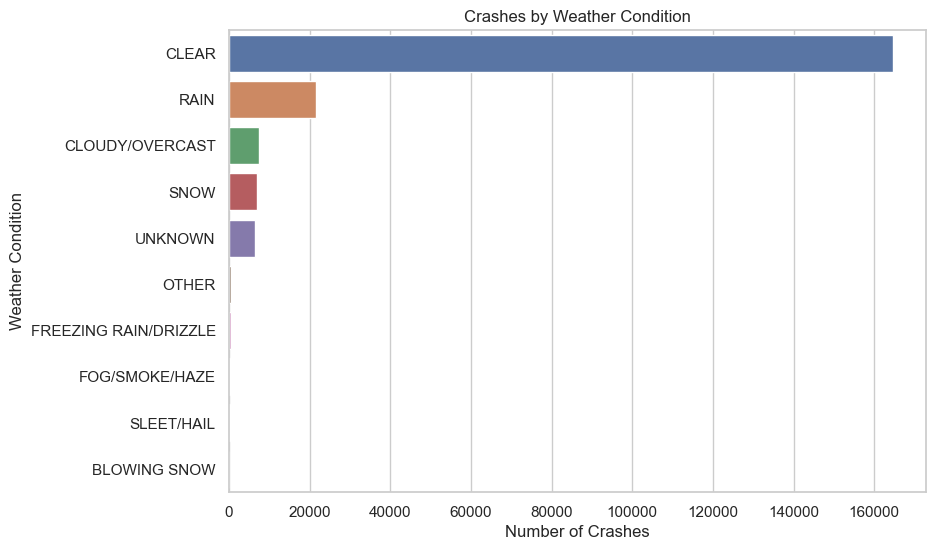

In [6]:
weather_counts = data['weather_condition'].value_counts()
display(weather_counts)

plt.figure(figsize=(9,6))
sns.barplot(x=weather_counts.head(10).values, y=weather_counts.head(10).index)
plt.title('Crashes by Weather Condition')
plt.xlabel('Number of Crashes')
plt.ylabel('Weather Condition')
plt.show()

**Analysis:** Most crashes are recorded under **CLEAR** weather conditions, followed by **RAIN** and **CLOUDY/OVERCAST**. This indicates that a large number of crashes occur during normal weather, although adverse weather can still affect injury rates.

# Q4. How are crashes distributed across lighting conditions?

lighting_condition
DAYLIGHT                  134083
DARKNESS, LIGHTED ROAD     53375
DARKNESS                    7436
DUSK                        6322
UNKNOWN                     4336
DAWN                        3723
Name: count, dtype: int64

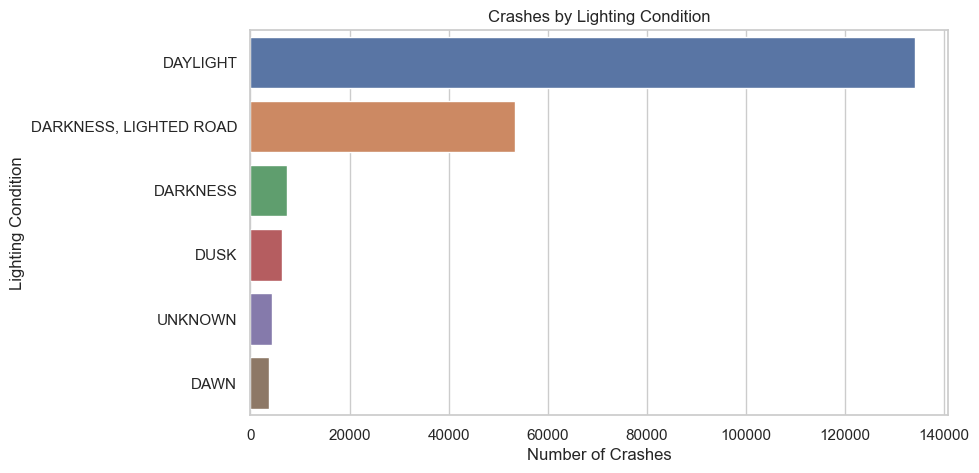

In [7]:
light_counts = data['lighting_condition'].value_counts()
display(light_counts)

plt.figure(figsize=(9,5))
sns.barplot(x=light_counts.values, y=light_counts.index)
plt.title('Crashes by Lighting Condition')
plt.xlabel('Number of Crashes')
plt.ylabel('Lighting Condition')
plt.show()

**Analysis:** **DAYLIGHT** has the largest number of crashes, followed by **DARKNESS, LIGHTED ROAD**. The raw number of crashes is strongly influenced by how much travel occurs under each lighting condition.

# Q5. Which hours of the day have the most crashes?

crash_hour
17    16095
16    16020
15    15890
18    13429
14    13346
13    11947
12    11725
8     11379
11    10050
19     9682
Name: count, dtype: int64

c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


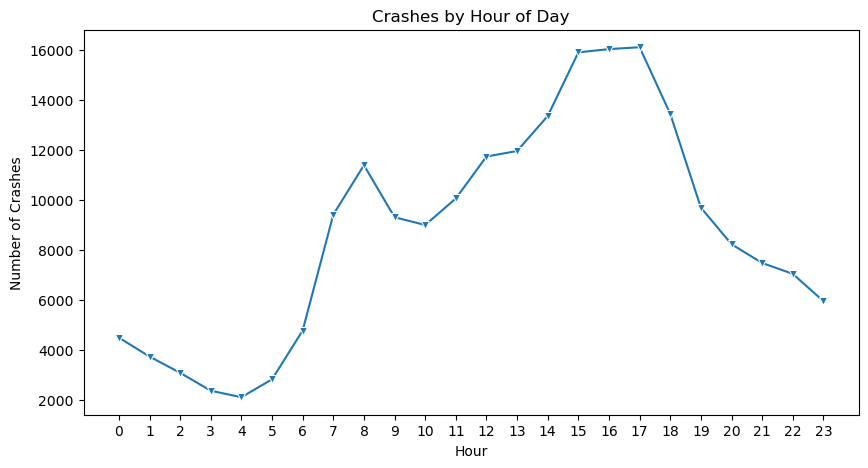

In [9]:
hour_counts = data['crash_hour'].value_counts().sort_index()
display(hour_counts.sort_values(ascending=False).head(10))

plt.figure(figsize=(10,5))
sns.lineplot(x=hour_counts.index, y=hour_counts.values, marker='v')
plt.title('Crashes by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Crashes')
plt.xticks(range(24))
plt.show()

**Analysis:** Crash frequency rises strongly during the afternoon. The highest counts occur around **17:00, 16:00 and 15:00**, with 17:00 having the highest number of crashes.

# Q6. Which days of the week record the most crashes?

day_name
Monday       27930
Tuesday      30068
Wednesday    30089
Thursday     30784
Friday       34453
Saturday     30706
Sunday       25245
Name: count, dtype: int64

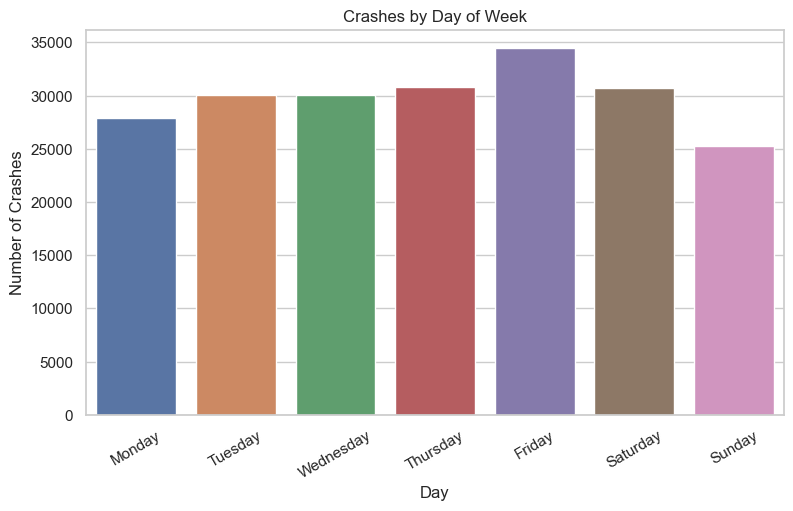

In [9]:
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
day_counts = data['day_name'].value_counts().reindex(day_order)
display(day_counts)

plt.figure(figsize=(9,5))
sns.barplot(x=day_counts.index, y=day_counts.values)
plt.title('Crashes by Day of Week')
plt.xlabel('Day')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=30)
plt.show()

**Analysis:** **Friday** has the highest number of recorded crashes, followed by Saturday and Thursday. Sunday has the lowest crash count among the seven days.

# Q7. Which months record the most crashes?

month_name
January      16605
February     14617
March        15264
April        15095
May          17429
June         17848
July         17831
August       18346
September    19013
October      20088
November     18326
December     18813
Name: count, dtype: int64

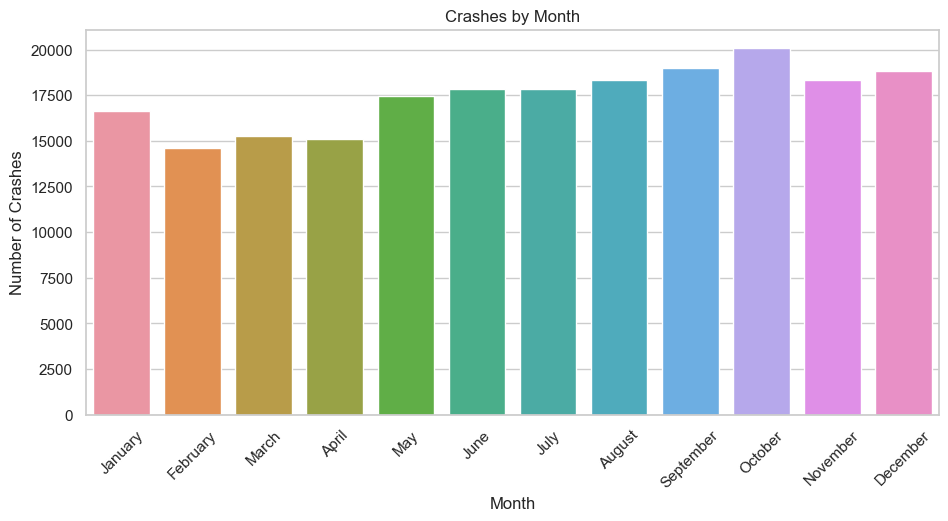

In [10]:
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
month_counts = data['month_name'].value_counts().reindex(month_order)
display(month_counts)

plt.figure(figsize=(11,5))
sns.barplot(x=month_counts.index, y=month_counts.values)
plt.title('Crashes by Month')
plt.xlabel('Month')
plt.ylabel('Number of Crashes')
plt.xticks(rotation=45)
plt.show()

**Analysis:** **October** records the highest number of crashes, followed by September and December. February has the lowest number of recorded crashes in this dataset.

# Q8. What are the most common primary contributory causes?

prim_contributory_cause
UNABLE TO DETERMINE                       58310
FAILING TO YIELD RIGHT-OF-WAY             42909
FOLLOWING TOO CLOSELY                     19074
DISREGARDING TRAFFIC SIGNALS              14590
IMPROPER TURNING/NO SIGNAL                12642
FAILING TO REDUCE SPEED TO AVOID CRASH    10675
IMPROPER OVERTAKING/PASSING                8302
DISREGARDING STOP SIGN                     6746
IMPROPER LANE USAGE                        6460
NOT APPLICABLE                             5241
Name: count, dtype: int64

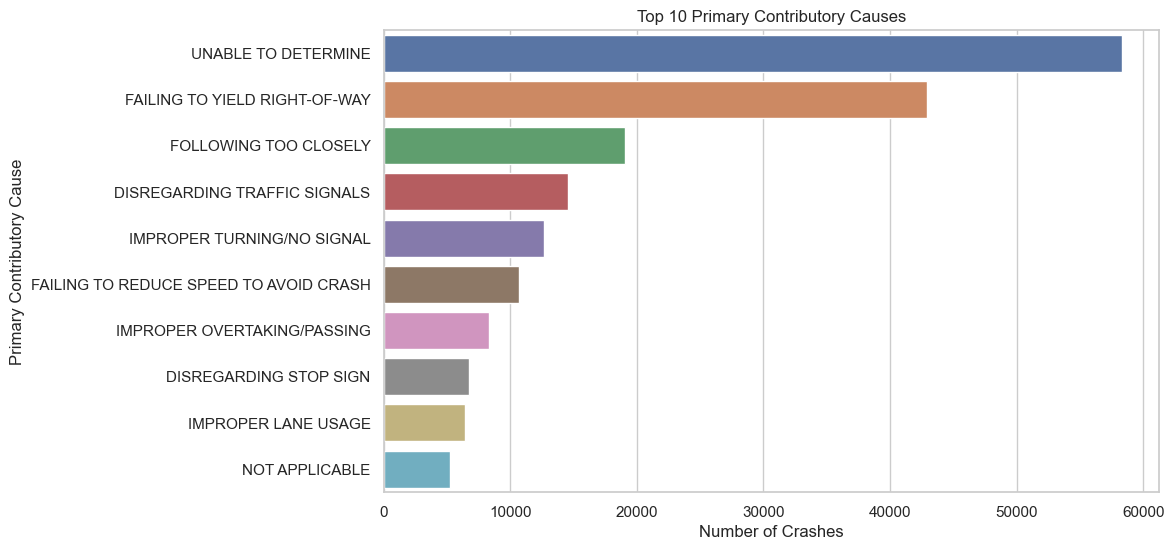

In [11]:
cause_counts = data['prim_contributory_cause'].value_counts().head(10)
display(cause_counts)

plt.figure(figsize=(10,6))
sns.barplot(x=cause_counts.values, y=cause_counts.index)
plt.title('Top 10 Primary Contributory Causes')
plt.xlabel('Number of Crashes')
plt.ylabel('Primary Contributory Cause')
plt.show()

**Analysis:** **UNABLE TO DETERMINE** is the largest recorded category. Among identifiable causes, **FAILING TO YIELD RIGHT-OF-WAY**, **FOLLOWING TOO CLOSELY**, **DISREGARDING TRAFFIC SIGNALS** and **IMPROPER TURNING/NO SIGNAL** are prominent.

# Q9. Which traffic control devices are most common?

traffic_control_device
TRAFFIC SIGNAL              123923
STOP SIGN/FLASHER            49131
NO CONTROLS                  29507
UNKNOWN                       4455
OTHER                          669
YIELD                          468
PEDESTRIAN CROSSING SIGN       247
OTHER REG. SIGN                181
LANE USE MARKING               153
FLASHING CONTROL SIGNAL        150
Name: count, dtype: int64

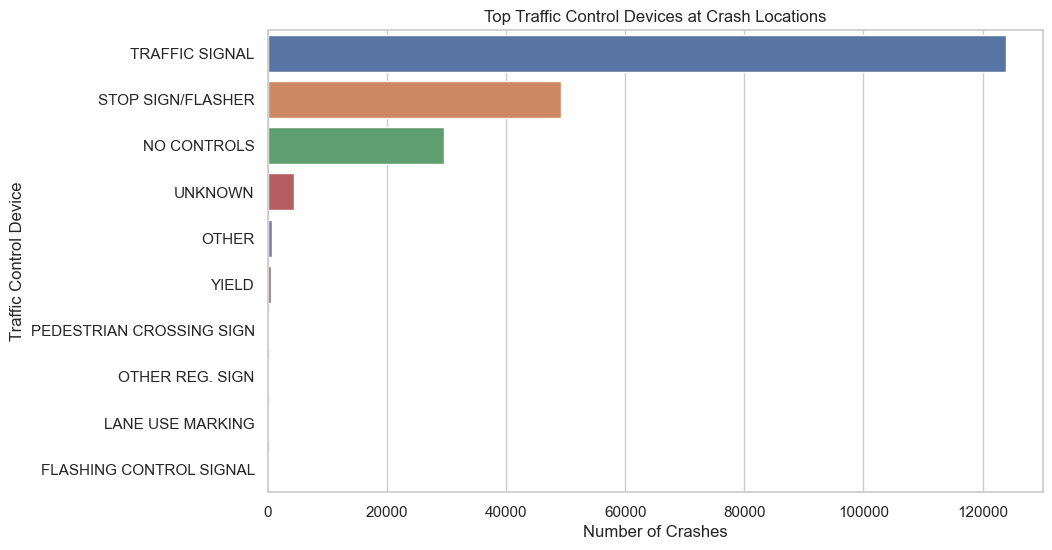

In [12]:
device_counts = data['traffic_control_device'].value_counts().head(10)
display(device_counts)

plt.figure(figsize=(10,6))
sns.barplot(x=device_counts.values, y=device_counts.index)
plt.title('Top Traffic Control Devices at Crash Locations')
plt.xlabel('Number of Crashes')
plt.ylabel('Traffic Control Device')
plt.show()

**Analysis:** **TRAFFIC SIGNAL** is the most common traffic-control category, followed by **STOP SIGN/FLASHER** and **NO CONTROLS**.

# Q10. Which trafficway types have the most crashes?

trafficway_type
NOT DIVIDED                        77737
FOUR WAY                           49050
DIVIDED - W/MEDIAN (NOT RAISED)    34217
ONE-WAY                            12340
DIVIDED - W/MEDIAN BARRIER         10719
T-INTERSECTION                      9232
OTHER                               4756
CENTER TURN LANE                    2862
UNKNOWN INTERSECTION TYPE           1885
FIVE POINT, OR MORE                 1119
Name: count, dtype: int64

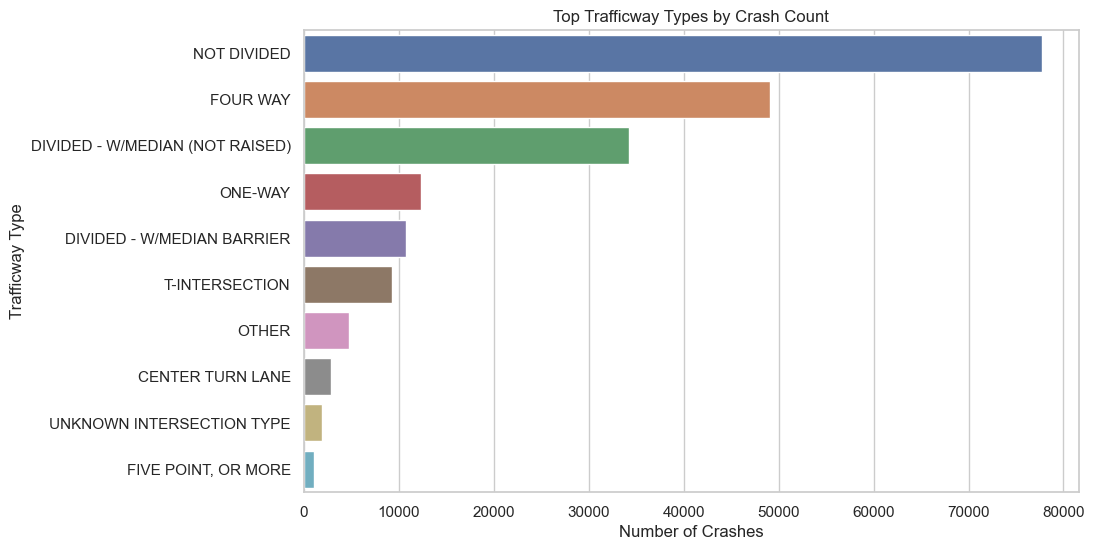

In [13]:
trafficway_counts = data['trafficway_type'].value_counts().head(10)
display(trafficway_counts)

plt.figure(figsize=(10,6))
sns.barplot(x=trafficway_counts.values, y=trafficway_counts.index)
plt.title('Top Trafficway Types by Crash Count')
plt.xlabel('Number of Crashes')
plt.ylabel('Trafficway Type')
plt.show()

**Analysis:** **NOT DIVIDED** roads have the largest number of recorded crashes, followed by **FOUR WAY** and **DIVIDED - W/MEDIAN (NOT RAISED)** trafficways.

# Q11. What is the distribution of road surface conditions?

roadway_surface_cond
DRY                155878
WET                 32906
UNKNOWN             12509
SNOW OR SLUSH        6201
ICE                  1303
OTHER                 438
SAND, MUD, DIRT        40
Name: count, dtype: int64

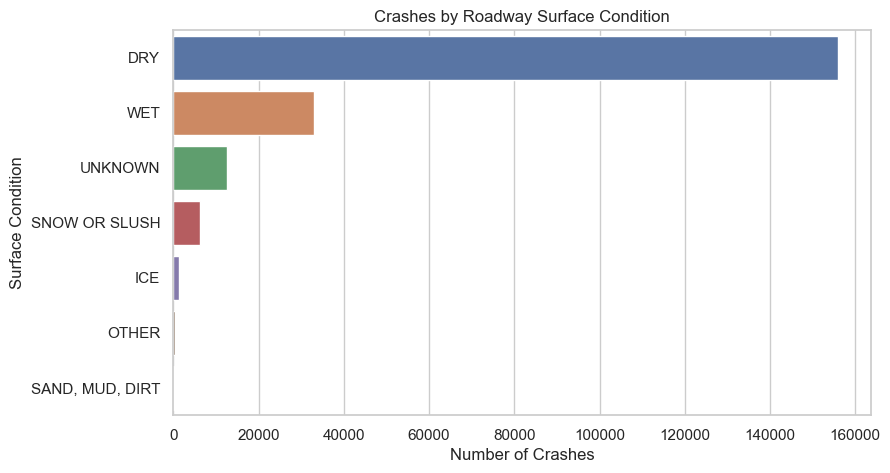

In [14]:
surface_counts = data['roadway_surface_cond'].value_counts()
display(surface_counts)

plt.figure(figsize=(9,5))
sns.barplot(x=surface_counts.values, y=surface_counts.index)
plt.title('Crashes by Roadway Surface Condition')
plt.xlabel('Number of Crashes')
plt.ylabel('Surface Condition')
plt.show()

**Analysis:** Most crashes occur on **DRY** road surfaces, followed by **WET** surfaces. Wet surfaces have a somewhat higher injury-crash rate than dry surfaces in this dataset.

# Q12. How are crashes distributed by damage level?

damage
OVER $1,500      147294
$501 - $1,500     41203
$500 OR LESS      20778
Name: count, dtype: int64

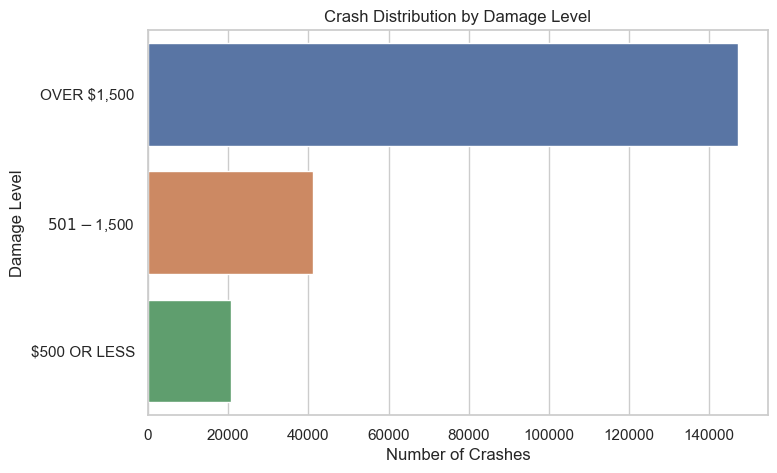

In [15]:
damage_counts = data['damage'].value_counts()
display(damage_counts)

plt.figure(figsize=(8,5))
sns.barplot(x=damage_counts.values, y=damage_counts.index)
plt.title('Crash Distribution by Damage Level')
plt.xlabel('Number of Crashes')
plt.ylabel('Damage Level')
plt.show()

**Analysis:** **OVER $1,500** is the most common damage category, accounting for the majority of recorded crashes.

# Q13. Which injury severity category is most common?

most_severe_injury
NO INDICATION OF INJURY     154767
NONINCAPACITATING INJURY     31521
REPORTED, NOT EVIDENT        16073
INCAPACITATING INJURY         6563
FATAL                          351
Name: count, dtype: int64

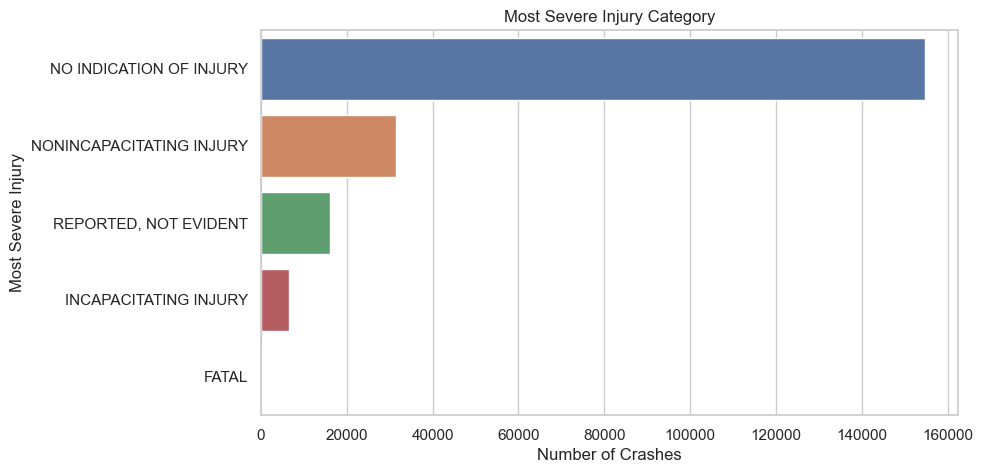

In [17]:
severity_counts = data['most_severe_injury'].value_counts()
display(severity_counts)

plt.figure(figsize=(9,5))
sns.barplot(x=severity_counts.values, y=severity_counts.index)
plt.title('Most Severe Injury Category')
plt.xlabel('Number of Crashes')
plt.ylabel('Most Severe Injury')
plt.show()

**Analysis:** **NO INDICATION OF INJURY** is the most common severity category. Among injury categories, **NONINCAPACITATING INJURY** is the largest group. The dataset records **351 crashes with a fatal most-severe-injury category** before duplicate removal, with 350 after duplicate removal.

# Q14. Which first-crash types have the highest injury rates?

In [18]:
injury_by_first = data.groupby('first_crash_type').agg(
    crashes=('first_crash_type','size'),
    injury_crashes=('injury_crash','sum'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
)
injury_by_first['injury_rate_%'] = 100 * injury_by_first['injury_crashes'] / injury_by_first['crashes']
display(injury_by_first.sort_values('injury_rate_%', ascending=False).head(10).round(2))

,crashes,injury_crashes,total_injuries,fatalities,injury_rate_%
first_crash_type,,,,,
PEDESTRIAN,8995,8054,8629.0,95.0,89.54
PEDALCYCLIST,5335,4027,4122.0,15.0,75.48
TRAIN,8,5,5.0,0.0,62.50
OVERTURNED,96,47,61.0,0.0,48.96
OTHER NONCOLLISION,249,100,104.0,0.0,40.16
HEAD ON,1790,699,1271.0,3.0,39.05
ANGLE,52243,17101,29063.0,123.0,32.73
OTHER OBJECT,759,247,291.0,5.0,32.54
FIXED OBJECT,4742,1243,1646.0,41.0,26.21


**Analysis:** **PEDESTRIAN** crashes have the highest injury rate among the major crash types (about **89.5%**), followed by **PEDALCYCLIST** crashes (about **75.5%**). This is an important safety finding even though these crash types are less frequent than turning or angle crashes.

# Q15. How does injury rate vary with weather?

,crashes,injury_crashes,total_injuries,fatalities,injury_rate_%
weather_condition,,,,,
CLEAR,164673,43405,64288.0,323.0,26.36
RAIN,21702,6180,8931.0,41.0,28.48
CLOUDY/OVERCAST,7532,1974,2781.0,13.0,26.21
SNOW,6869,1499,2118.0,3.0,21.82
UNKNOWN,6534,849,1085.0,6.0,12.99
OTHER,627,204,303.0,0.0,32.54
FREEZING RAIN/DRIZZLE,510,160,235.0,1.0,31.37
FOG/SMOKE/HAZE,360,107,160.0,1.0,29.72
SLEET/HAIL,308,99,142.0,0.0,32.14


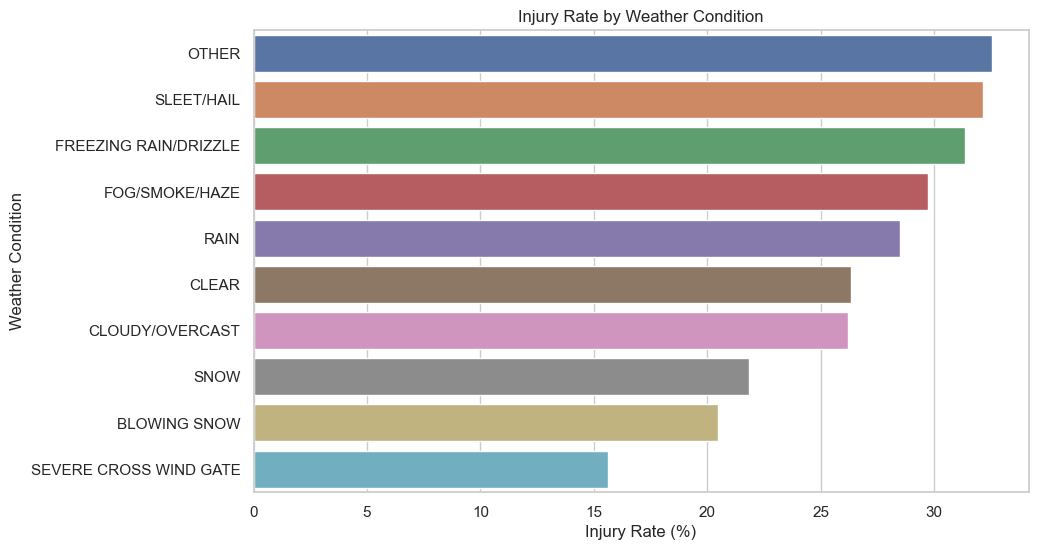

In [19]:
weather_injury = data.groupby('weather_condition').agg(
    crashes=('weather_condition','size'),
    injury_crashes=('injury_crash','sum'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
)
weather_injury['injury_rate_%'] = 100 * weather_injury['injury_crashes'] / weather_injury['crashes']
display(weather_injury.sort_values('crashes', ascending=False).round(2))

plt.figure(figsize=(10,6))
plot_data = weather_injury.sort_values('injury_rate_%', ascending=False).head(10)
sns.barplot(x=plot_data['injury_rate_%'].values, y=plot_data.index)
plt.title('Injury Rate by Weather Condition')
plt.xlabel('Injury Rate (%)')
plt.ylabel('Weather Condition')
plt.show()

**Analysis:** CLEAR weather has the largest crash count because it is the most common condition. **RAIN** has a higher injury rate than CLEAR (about **28.5% vs 26.4%**). Therefore, frequency and injury risk should be considered separately.

# Q16. How does injury rate vary with lighting?

In [20]:
lighting_injury = data.groupby('lighting_condition').agg(
    crashes=('lighting_condition','size'),
    injury_crashes=('injury_crash','sum'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
)
lighting_injury['injury_rate_%'] = 100 * lighting_injury['injury_crashes'] / lighting_injury['crashes']
display(lighting_injury.sort_values('injury_rate_%', ascending=False).round(2))

,crashes,injury_crashes,total_injuries,fatalities,injury_rate_%
lighting_condition,,,,,
"DARKNESS, LIGHTED ROAD",53375,15718,24416.0,187.0,29.45
DARKNESS,7436,2064,3015.0,29.0,27.76
DAWN,3723,1026,1446.0,5.0,27.56
DUSK,6322,1636,2352.0,13.0,25.88
DAYLIGHT,134083,33528,48185.0,154.0,25.01
UNKNOWN,4336,536,677.0,1.0,12.36


**Analysis:** **DARKNESS, LIGHTED ROAD** has a higher injury rate (about **29.5%**) than DAYLIGHT (about **25.0%**). Darkness-related conditions therefore deserve attention when examining crash severity.

# Q17. How does injury rate vary with road surface condition?

In [21]:
surface_injury = data.groupby('roadway_surface_cond').agg(
    crashes=('roadway_surface_cond','size'),
    injury_crashes=('injury_crash','sum'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
)
surface_injury['injury_rate_%'] = 100 * surface_injury['injury_crashes'] / surface_injury['crashes']
display(surface_injury.sort_values('injury_rate_%', ascending=False).round(2))

,crashes,injury_crashes,total_injuries,fatalities,injury_rate_%
roadway_surface_cond,,,,,
OTHER,438,135,197.0,1.0,30.82
WET,32906,9384,13597.0,55.0,28.52
"SAND, MUD, DIRT",40,11,14.0,0.0,27.50
DRY,155878,41530,61661.0,316.0,26.64
SNOW OR SLUSH,6201,1227,1709.0,4.0,19.79
ICE,1303,252,337.0,4.0,19.34
UNKNOWN,12509,1969,2576.0,9.0,15.74


**Analysis:** WET roads show an injury rate of about **28.5%**, compared with about **26.6%** for DRY roads. The result suggests that wet conditions may be associated with greater injury risk, although this EDA alone does not establish causation.

# Q18. Which hours have the highest total number of injuries?

,crashes,total_injuries,fatalities
crash_hour,,,
17,16095,5547.0,24.0
16,16020,5541.0,11.0
15,15890,5407.0,19.0
18,13429,4835.0,20.0
14,13346,4711.0,12.0
13,11947,4137.0,11.0
12,11725,4059.0,17.0
8,11379,3974.0,8.0
19,9682,3896.0,20.0


c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\HP\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


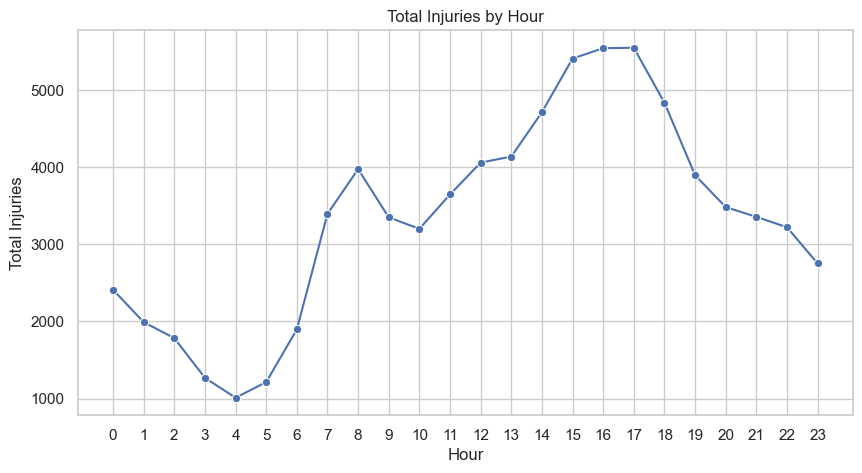

In [24]:
hour_injuries = data.groupby('crash_hour').agg(
    crashes=('crash_hour','size'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
).sort_values('total_injuries', ascending=False)
display(hour_injuries.head(10))

plt.figure(figsize=(10,5))
all_hour_injuries = hour_injuries.sort_index()
sns.lineplot(x=all_hour_injuries.index, y=all_hour_injuries['total_injuries'], marker='o')
plt.title('Total Injuries by Hour')
plt.xlabel('Hour')
plt.ylabel('Total Injuries')
plt.xticks(range(24))
plt.show()

**Analysis:** The afternoon/evening period has the largest injury totals. **17:00** has the highest total injuries, closely followed by **16:00 and 15:00**.

# Q19. Which days have the highest total injuries?

,crashes,total_injuries,fatalities
day_name,,,
Monday,27930,10601.0,44.0
Tuesday,30068,10941.0,41.0
Wednesday,30089,11292.0,65.0
Thursday,30784,11211.0,59.0
Friday,34453,12307.0,50.0
Saturday,30706,12343.0,65.0
Sunday,25245,11396.0,65.0


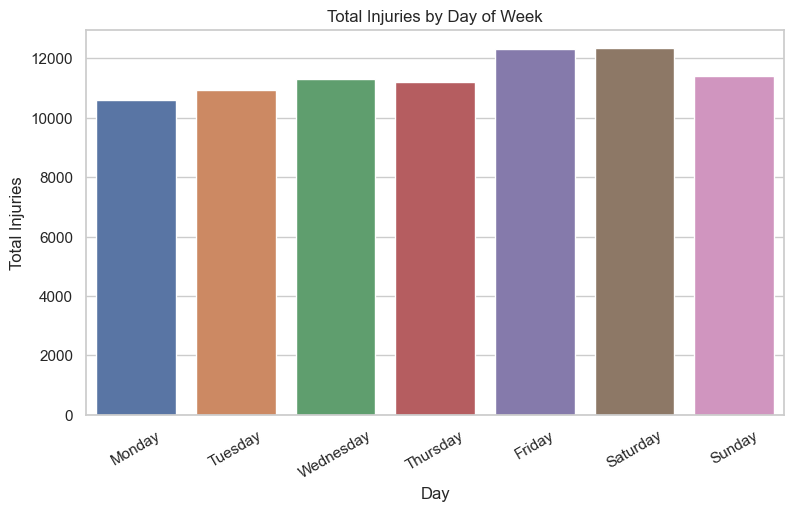

In [25]:
day_injuries = data.groupby('day_name').agg(
    crashes=('day_name','size'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
).reindex(day_order)
display(day_injuries)

plt.figure(figsize=(9,5))
sns.barplot(x=day_injuries.index, y=day_injuries['total_injuries'])
plt.title('Total Injuries by Day of Week')
plt.xlabel('Day')
plt.ylabel('Total Injuries')
plt.xticks(rotation=30)
plt.show()

**Analysis:** **Saturday** has the highest total number of injuries, closely followed by Friday. This is different from simply counting crashes, showing why both crash frequency and severity should be studied.

# Q20. Which months have the highest total injuries?

,crashes,total_injuries,fatalities
month_name,,,
October,20088,7918.0,46.0
September,19013,7727.0,30.0
July,17831,7584.0,41.0
August,18346,7491.0,40.0
June,17848,7230.0,30.0
May,17429,6950.0,38.0
November,18326,6842.0,38.0
December,18813,6695.0,26.0
April,15095,5777.0,25.0


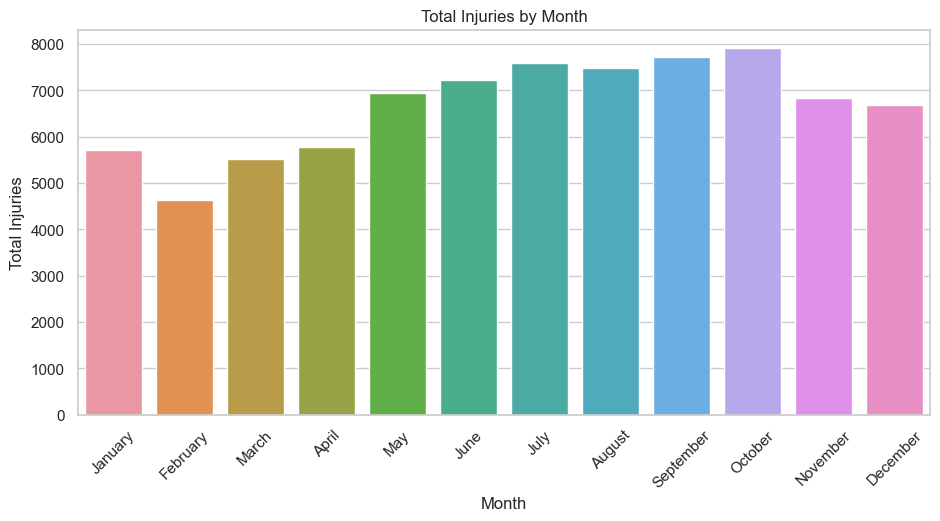

In [26]:
month_injuries = data.groupby('month_name').agg(
    crashes=('month_name','size'),
    total_injuries=('injuries_total','sum'),
    fatalities=('injuries_fatal','sum')
).reindex(month_order)
display(month_injuries.sort_values('total_injuries', ascending=False))

plt.figure(figsize=(11,5))
sns.barplot(x=month_injuries.index, y=month_injuries['total_injuries'])
plt.title('Total Injuries by Month')
plt.xlabel('Month')
plt.ylabel('Total Injuries')
plt.xticks(rotation=45)
plt.show()

**Analysis:** **October** records the highest total injuries, followed by September and July. These months also contain relatively high crash counts in the dataset.

## Conclusion

The EDA of the traffic-accident dataset reveals several clear patterns.

* The majority of records are **NO INJURY / DRIVE AWAY** crashes, but a substantial **43.9%** involve reported injuries.
* **TURNING, ANGLE and REAR END** are the most frequent first-crash types.
* Most crashes are recorded during **CLEAR weather and DAYLIGHT**, reflecting their high occurrence in the dataset.
* Crash frequency is highest during the **afternoon, especially around 15:00–17:00**, with 17:00 being the peak hour.
* **Friday** has the highest crash count, while **Saturday** has the highest total injuries.
* **October** has the highest crash count and the highest total injury count.
* **PEDESTRIAN and PEDALCYCLIST** crash types have much higher injury rates than common vehicle-to-vehicle crash types.
* **RAIN** and **WET road surfaces** show higher injury rates than CLEAR weather and DRY surfaces.
* **DISREGARDING TRAFFIC SIGNALS** has a particularly high injury rate among major contributory causes.
* The number of units involved has only a modest relationship with total injuries, showing that injury outcomes depend on more than the number of vehicles involved.

Overall, the analysis shows that **time, crash type, road/environmental conditions and contributory causes** are useful dimensions for understanding traffic-accident patterns. The results can support targeted safety planning, awareness campaigns and further statistical or predictive modelling.